# 05 · Transfer learning: a pretrained ResNet18 (deliverable 3)

A dense network flattens the painting and loses its 2-D structure (S05, S07). A **convolutional** network looks at small neighbourhoods with the same filters everywhere, and builds edges → textures → object parts → objects, layer after layer (S07).
With only ~2 300 training images we do not train a CNN from scratch: we start from a **ResNet18 pretrained on ImageNet** (1.2 million photos) and adapt it to our genres, as in TP07 Part D:

1. replace its last layer by a new one for our classes, **freeze** the rest and train the **head** only;
2. paintings are very different from ImageNet photos (S07, transfer-learning table): **unfreeze the last block** (`layer4`) and **fine-tune** it with a smaller learning rate;
3. compare both on validation, measure the chosen one **once** on the test set, with its CPU cost for the kiosk.

## 0. Setup

In [1]:
import copy, json, math, sys, time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, "../src")                 # the team's shared code
from museum_guide.data import prepare_subset

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

ROOT = Path("..")
IMG_SIZE = 128            # our images are 128x128 (TP07 uses 64 on a CPU; 224 = ImageNet, more accurate but slower)
FIG_DIR = ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR = ROOT / "results"
MODEL_DIR = ROOT / "data" / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)    # weights stay out of Git
print("device:", device)

device: mps


## 1. Prepare the images like the pre-training
*"A pretrained model must always receive inputs prepared like during its pre-training"* (TP07): resize, then normalise each channel with the **ImageNet** mean (0.485, 0.456, 0.406) and std (0.229, 0.224, 0.225) (S07).
`prepare_subset` gives the team's split (same images as every other model) but standardised with *our* statistics: we undo that first, back to pixels in [0, 1].

In [2]:
data = prepare_subset("genre", seed=SEED)
class_names = data["classes"]
C = len(class_names)
idx = {"train": data["train_idx"], "val": data["val_idx"], "test": data["test_idx"]}

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def prepare(X):
    X = X * data["std"] + data["mean"]                                           # undo the team standardisation: [0, 1]
    X = F.interpolate(X, size=IMG_SIZE, mode="bilinear", align_corners=False)    # resize
    return (X - IMAGENET_MEAN) / IMAGENET_STD                                    # ImageNet normalisation


X_img = prepare(data["X"])
y_all = data["y"]
data["X"] = None                                                                 # free the memory

full_set = TensorDataset(X_img, y_all)
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(Subset(full_set, idx["train"]), batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(Subset(full_set, idx["val"]), batch_size=128)
test_loader = DataLoader(Subset(full_set, idx["test"]), batch_size=128)

print(C, "classes:", class_names)
print("images:", tuple(X_img.shape), "|", {s: len(i) for s, i in idx.items()})
print("train mean per channel:", X_img[torch.as_tensor(idx["train"])].mean(dim=(0, 2, 3)).round(decimals=2).tolist())

11 classes: ['Unknown Genre', 'abstract_painting', 'cityscape', 'genre_painting', 'illustration', 'landscape', 'nude_painting', 'portrait', 'religious_painting', 'sketch_and_study', 'still_life']
images: (3300, 3, 128, 128) | {'train': 2309, 'val': 496, 'test': 495}
train mean per channel: [0.28999999165534973, 0.20000000298023224, 0.10999999940395355]


## 2. Load ResNet18, replace the head, freeze the backbone (S07)
`model.fc` is an `nn.Linear(512, 1000)` for the 1 000 ImageNet classes: we replace it by a new `nn.Linear(512, C)` (random weights).
`requires_grad = False`: autograd computes no gradient for these weights and the optimiser does not move them (S07).

In [3]:
def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


torch.manual_seed(SEED)
model = resnet18(weights=ResNet18_Weights.DEFAULT)       # weights learned on ImageNet (45 MB, downloaded once)
print("original head:", model.fc)
model.fc = nn.Linear(512, C)                              # new head for our genres
for p in model.parameters():
    p.requires_grad = False                               # freeze everything...
for p in model.fc.parameters():
    p.requires_grad = True                                # ...except the new head
model = model.to(device)

n_trainable = count_parameters(model, trainable_only=True)
print("new head:", model.fc)
print(f"trainable: {n_trainable:,} of {count_parameters(model):,} parameters  (512 x {C} + {C} = {512 * C + C})")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/carlachaume/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:06<00:00, 7.11MB/s]


original head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=11, bias=True)
trainable: 5,643 of 11,182,155 parameters  (512 x 11 + 11 = 5643)


## 3. Train the head (S04 loop, S06 early stopping)
- `fit_transfer` follows TP07: the model stays in `eval()` mode while training, so that the batch-norm layers keep the statistics learned on ImageNet (the trainable weights are still updated normally).
- Early stopping as in TP06 Exercise 10: keep a copy of the weights of the best validation epoch, stop after `patience` epochs without improvement, reload the best weights.
- Sanity check (S08): before training, the loss should be close to $\ln C$.

In [4]:
loss_fn = nn.CrossEntropyLoss()


def evaluate(model, loader, loss_fn):
    model.eval()
    total, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total += loss_fn(out, yb).item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total / n, correct / n


def fit_transfer(model, optimizer, max_epochs, patience):
    torch.manual_seed(1)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t0 = time.time()
    for epoch in range(1, max_epochs + 1):
        model.eval()                                  # batch norm keeps its ImageNet statistics (TP07)
        total, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                     # the 5 lines of the training loop (S04)
            out = model(xb)
            loss = loss_fn(out, yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(total / n); history["train_acc"].append(correct / n)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"epoch {epoch:2d} | train loss {total / n:.3f} acc {correct / n:.3f} | "
              f"val loss {val_loss:.3f} acc {val_acc:.3f} | {time.time() - t0:.0f} s")
        if val_loss < best_loss:                      # early stopping (TP06 Exercise 10)
            best_loss, best_state, best_epoch, wait = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
            if wait >= patience:
                print(f"early stopping: no improvement for {patience} epochs")
                break
    model.load_state_dict(best_state)                 # back to the best epoch
    history["best_epoch"], history["time_s"] = best_epoch, time.time() - t0
    return history


def plot_history(history, title, filename):
    e = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(e, history["train_loss"], label="train"); axes[0].plot(e, history["val_loss"], label="validation")
    axes[1].plot(e, history["train_acc"], label="train"); axes[1].plot(e, history["val_acc"], label="validation")
    for ax, name in zip(axes, ["loss", "accuracy"]):
        ax.axvline(history["best_epoch"], ls="--", c="grey", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel(name)
        ax.legend(); ax.grid(alpha=.3)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / filename, dpi=150); plt.show()


init_loss, init_acc = evaluate(model, val_loader, loss_fn)
print(f"before training: val loss {init_loss:.3f} (ln C = {math.log(C):.3f}), val acc {init_acc:.3f} (chance {1 / C:.3f})")

before training: val loss 2.862 (ln C = 2.398), val acc 0.083 (chance 0.091)


epoch  1 | train loss 2.143 acc 0.267 | val loss 1.648 acc 0.460 | 11 s
epoch  2 | train loss 1.458 acc 0.512 | val loss 1.452 acc 0.540 | 16 s
epoch  3 | train loss 1.275 acc 0.571 | val loss 1.394 acc 0.571 | 21 s
epoch  4 | train loss 1.195 acc 0.611 | val loss 1.374 acc 0.560 | 25 s
epoch  5 | train loss 1.102 acc 0.636 | val loss 1.368 acc 0.558 | 30 s
epoch  6 | train loss 1.056 acc 0.658 | val loss 1.375 acc 0.565 | 36 s
epoch  7 | train loss 1.006 acc 0.665 | val loss 1.374 acc 0.562 | 42 s
epoch  8 | train loss 0.966 acc 0.680 | val loss 1.364 acc 0.571 | 46 s
epoch  9 | train loss 0.953 acc 0.687 | val loss 1.369 acc 0.567 | 51 s
epoch 10 | train loss 0.911 acc 0.699 | val loss 1.368 acc 0.575 | 56 s
epoch 11 | train loss 0.889 acc 0.709 | val loss 1.410 acc 0.552 | 61 s
early stopping: no improvement for 3 epochs


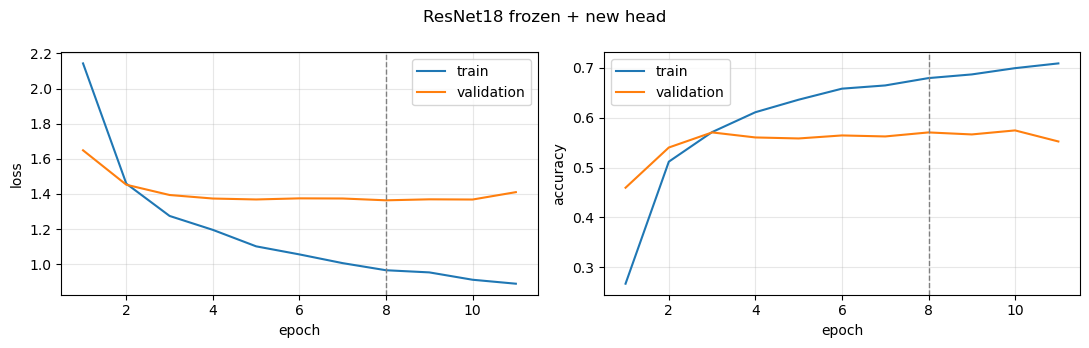

head only: best validation accuracy 0.571 at epoch 8 (61 s)


In [5]:
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)      # the head only (S07)
history_head = fit_transfer(model, optimizer, max_epochs=15, patience=3)
acc_head = history_head["val_acc"][history_head["best_epoch"] - 1]
torch.save(model.state_dict(), MODEL_DIR / "resnet18_head.pt")
plot_history(history_head, "ResNet18 frozen + new head", "resnet_head_curves.png")
print(f"head only: best validation accuracy {acc_head:.3f} at epoch {history_head['best_epoch']} "
      f"({history_head['time_s']:.0f} s)")

**Reading:** with the backbone frozen, only the new head (5 643 parameters) is trained. Learning is fast: the validation accuracy reaches 57 % at epoch 3, then plateaus around 56-57 % while the training accuracy keeps rising (from 57 % to 71 %): the gap between train and validation opens, the start of over-fitting. At epoch 11 the validation loss goes back up (1.41), so early stopping stops the run and reloads the weights of epoch 8, the best validation loss (1.364). **Best validation accuracy: 57.1 %**, more than twice the logistic regression on pixels (26.8 %) and 6 times chance (9.1 %), in 61 s of training. Same kind of classifier as the baseline (one neuron per genre), but on the 512 ResNet features instead of raw pixels: the pretrained convolutions see shapes and objects. The plateau shows the limit of frozen features learned on photos: fine-tuning the last block should adapt them to paintings (next issue).

## 4. Fine-tune the last block (S07, TP07 Exercise 16)
`layer4` computes the most specific features, the ones most tied to ImageNet photos. Paintings are "very different" data (S07): we unfreeze `layer4` and train it with the head, with **two learning rates** (parameter groups): small for the pretrained weights (we only adjust them, we do not want to destroy them), larger for the head.

In [6]:
for p in model.layer4.parameters():
    p.requires_grad = True
optimizer = torch.optim.Adam([{"params": model.layer4.parameters(), "lr": 1e-4},
                              {"params": model.fc.parameters(), "lr": 1e-3}])
print(f"trainable: {count_parameters(model, trainable_only=True):,} of {count_parameters(model):,} parameters "
      f"(layer4: {count_parameters(model.layer4):,})")

trainable: 8,399,371 of 11,182,155 parameters (layer4: 8,393,728)
